In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
"""
Implementasi algoritma perceptron
"""
class Perceptron:
    def __init__(self, learning_rate=0.1, epoch = 20):
        self.learning_rate = learning_rate
        self.epoch = epoch
        self.weights = None
        self.bias = None
        self.errors = []

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, 0)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        for _ in range(self.epoch):
            errors = 0
            for xi, target in zip(X, y):
                linear_output = np.dot(xi, self.weights) + self.bias
                y_pred = np.where(linear_output >= 0, 1, 0)
                update = self.learning_rate * (target - y_pred)
                self.weights += update * xi
                self.bias += update
                errors += int(update != 0.0)
            self.errors.append(errors)

In [3]:
def plot_decision_boundary(X, y, model, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.8, cmap='bwr')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap='bwr')
    plt.title(title)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.show()

In [4]:
# Data untuk OR
X_or = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])
y_or = np.array([0, 1, 1, 1])

# Data untuk XOR
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

Weights: [0.1 0.1]
Bias: -0.1
Predictions: [0 1 1 1]


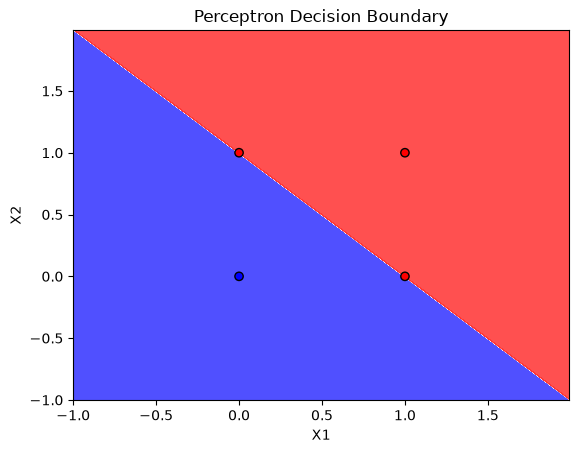

In [5]:
perceptron = Perceptron(learning_rate=0.1, epoch=20)
perceptron.fit(X_or, y_or)

print("Weights:", perceptron.weights)
print("Bias:", perceptron.bias)
print("Predictions:", perceptron.predict(X_or))
plot_decision_boundary(X_or, y_or, perceptron, "Perceptron Decision Boundary")

Weights: [-0.1  0. ]
Bias: 0.0
Predictions: [1 1 0 0]


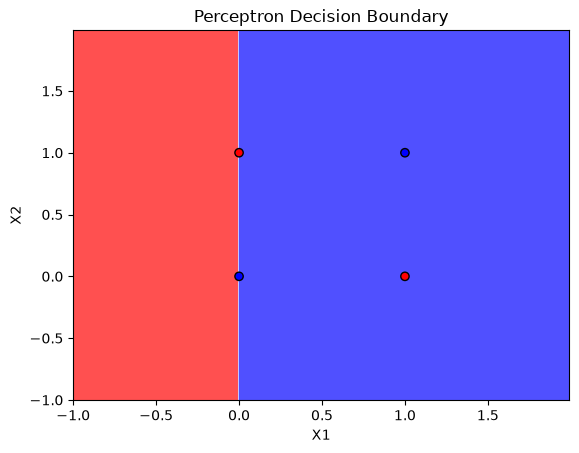

In [6]:
perceptron = Perceptron(learning_rate=0.1, epoch=20)
perceptron.fit(X_xor, y_xor)

print("Weights:", perceptron.weights)
print("Bias:", perceptron.bias)
print("Predictions:", perceptron.predict(X_xor))
plot_decision_boundary(X_xor, y_xor, perceptron, "Perceptron Decision Boundary")